# 11 - Bank network and country corridors (Dashboard 8)

**Question:** which banks and countries does the generator connect, and how does it pick the intermediary banks of a route?

Columns studied: `bic8_path` (first bank, last bank, intermediaries), with the country inside each BIC (characters 5-6) and `currency_code`.

- "First bank" and "last bank" are the ends of `bic8_path`: notebook `09_routing` showed the route is built around them (rule R-R5). Countries here are therefore the countries of the route, not of the party's own bank.
- Data: `feat` view through `src/eda.py`, DuckDB, UTC. No outside data is used: every "expected" figure is computed from the dataset itself.
- Charts are saved to `reports/figures/` with the prefix `N`.

Run the cells top to bottom.

## 0. Setup

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works whether Jupyter was started in the project root or in notebooks/
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
assert (ROOT / "src").exists(), f"Project root not found from {Path.cwd()}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import eda
from src import settings as S

con = eda.connect()
q = eda.q

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

EXPECTED_ROWS = 10_000_000
BLUE, ORANGE, RED, GREEN, GREY = "#4C72B0", "#DD8452", "#C44E52", "#55A868", "#8C8C8C"

tx     10,000,000 rows x 21 columns
feat   10,000,000 rows x 40 columns
DuckDB 2.0.0 | time zone UTC


### Working tables
`net`: one row per payment with the two ends of the route. `mid`: one row per intermediary bank (every path entry between the first and the last, gaps excluded). `bank`: one row per bank with how often it appears in each role.

In [2]:
con.execute("""
    CREATE OR REPLACE TEMP TABLE net AS
    SELECT split_part(bic8_path, ';', 1)                    AS first_bank,
           string_split(bic8_path, ';')[-1]                 AS last_bank,
           substr(split_part(bic8_path, ';', 1), 5, 2)      AS first_country,
           substr(string_split(bic8_path, ';')[-1], 5, 2)   AS last_country,
           participant_count AS banks, currency_code, string_split(bic8_path, ';') AS hops,
           ordering_account, path_first_differs
    FROM feat
""")
con.execute("""
    CREATE OR REPLACE TEMP TABLE mid AS
    SELECT bank, substr(bank, 5, 2) AS country, first_bank, last_bank, first_country, last_country, currency_code
    FROM (SELECT unnest(list_slice(hops, 2, len(hops) - 1)) AS bank, first_bank, last_bank, first_country, last_country, currency_code
          FROM net WHERE banks >= 3)
    WHERE bank <> '...'
""")
con.execute("""
    CREATE OR REPLACE TEMP TABLE bank AS
    SELECT bic, substr(bic, 5, 2) AS country, sum(as_first) AS as_first, sum(as_last) AS as_last, sum(as_mid) AS as_intermediary
    FROM (SELECT first_bank AS bic, count(*) AS as_first, 0 AS as_last, 0 AS as_mid FROM net GROUP BY 1
          UNION ALL SELECT last_bank, 0, count(*), 0 FROM net GROUP BY 1
          UNION ALL SELECT bank, 0, 0, count(*) FROM mid GROUP BY 1)
    GROUP BY 1
""")
N = int(q("SELECT count(*) AS n FROM net").loc[0, "n"])
assert N == EXPECTED_ROWS, f"Expected {EXPECTED_ROWS:,} rows, found {N:,}"
N_MID = int(q("SELECT count(*) AS n FROM mid").loc[0, "n"])
N_MULTI = int(q("SELECT count(*) AS n FROM net WHERE banks >= 3").loc[0, "n"])
q("""SELECT count(*) AS banks_in_any_role, sum((as_first > 0)::INT) AS seen_as_first_bank, sum((as_last > 0)::INT) AS seen_as_last_bank,
            sum((as_intermediary > 0)::INT) AS seen_as_intermediary, count(DISTINCT country) AS countries FROM bank""")

,banks_in_any_role,seen_as_first_bank,seen_as_last_bank,seen_as_intermediary,countries
0,8727,"8,386.000","8,268.000","7,506.000",229


## 1. Hypotheses

H-N1 to H-N4 were written **before testing**. H-N5 and H-N6 were added after the first results (see the note under the table).

| ID | Hypothesis | Test |
|---|---|---|
| H-N1 | A few hub banks, mostly in the US, Switzerland and the UK, carry most of the intermediary traffic | Concentration of intermediary appearances; share of multi-bank routes that touch a top hub |
| H-N2 | Country-to-country traffic is just "big sends to big": the volume of a corridor is the product of the two countries' sizes, with few domestic payments | Observed corridor volume against sender share x receiver share |
| H-N3 | The intermediary depends on the currency (dollar payments go through US banks) | Country of the intermediaries by currency |
| H-N4 | Intermediaries sit near the route: in the country of the first or the last bank | Share of intermediaries in the same country as an end, against chance |
| H-N5 | *(added)* Traffic is concentrated on a small set of bank pairs, driven by a few very large sender accounts | Share of payments on the busiest pairs; sender accounts behind them |
| H-N6 | *(added)* An intermediary is drawn from all banks with a weight that grows faster than the bank's own traffic | Share of intermediary slots against share of end-of-route slots, by bank size |

**How the hypotheses changed.** H-N2 failed in an unexpected way: corridors deviate a lot from "big sends to big", in both directions. The largest deviations traced back to single pairs of banks with thousands of payments, which led to H-N5. H-N4 failed (intermediaries ignore geography), which raised the question of how they *are* chosen (H-N6).

## 2. Banks: how concentrated is the traffic? (H-N1)

In [3]:
def concentration(column, label):
    d = q(f"SELECT {column} AS n FROM bank WHERE {column} > 0 ORDER BY 1 DESC")
    cum = d.n.cumsum() / d.n.sum()
    return {"role": label, "banks": len(d), "appearances": int(d.n.sum()),
            "top 10 banks (%)": 100 * cum.iloc[min(9, len(d) - 1)], "top 100 banks (%)": 100 * cum.iloc[min(99, len(d) - 1)],
            "banks needed for half": int((cum >= 0.5).idxmax()) + 1, "banks needed for 90%": int((cum >= 0.9).idxmax()) + 1}, cum

rows, curves = [], {}
for column, label in [("as_first", "first bank"), ("as_last", "last bank"), ("as_intermediary", "intermediary")]:
    row, cum = concentration(column, label)
    rows.append(row)
    curves[label] = cum
conc = pd.DataFrame(rows).set_index("role")
conc.round(2)

,banks,appearances,top 10 banks (%),top 100 banks (%),banks needed for half,banks needed for 90%
role,,,,,,
first bank,8386,10000000,8.940,32.600,236,1596
last bank,8268,10000000,11.250,37.340,185,1401
intermediary,7506,5815715,19.220,51.900,91,731


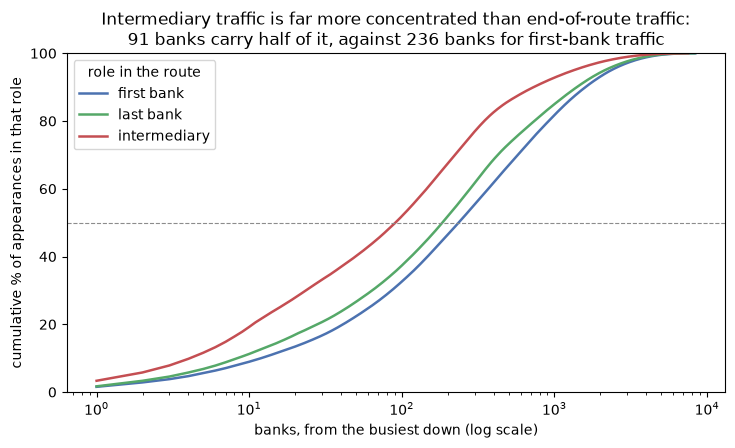

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for (label, cum), color in zip(curves.items(), [BLUE, GREEN, RED]):
    ax.plot(np.arange(1, len(cum) + 1), 100 * cum, color=color, lw=1.8, label=label)
ax.set_xscale("log")
ax.set_xlabel("banks, from the busiest down (log scale)")
ax.set_ylabel("cumulative % of appearances in that role")
ax.set_ylim(0, 100)
ax.axhline(50, color=GREY, ls="--", lw=0.8)
ax.legend(title="role in the route")
ax.set_title(f"Intermediary traffic is far more concentrated than end-of-route traffic:\n"
             f"{conc.loc['intermediary', 'banks needed for half']} banks carry half of it, against "
             f"{conc.loc['first bank', 'banks needed for half']} banks for first-bank traffic")
eda.save(fig, "N1_bank_concentration")
plt.show()

In [5]:
hubs = q(f"""
    SELECT bic, country, as_intermediary, 100.0 * as_intermediary / {N_MID} AS pct_of_intermediary_slots,
           100.0 * as_first / {N} AS pct_of_first_bank_slots, 100.0 * as_last / {N} AS pct_of_last_bank_slots
    FROM bank ORDER BY as_intermediary DESC LIMIT 10
""")
by_country = q(f"""
    SELECT country, count(*) AS intermediary_slots, 100.0 * count(*) / {N_MID} AS pct_of_intermediary_slots
    FROM mid GROUP BY 1 ORDER BY 2 DESC LIMIT 8
""")
display(hubs.round(3))
by_country.round(2)

,bic,country,as_intermediary,pct_of_intermediary_slots,pct_of_first_bank_slots,pct_of_last_bank_slots
0,0309CHZ0,CH,"193,613.000",3.329,1.302,1.689
1,0004IMD0,IM,"142,644.000",2.453,1.542,1.638
2,0085BEB0,BE,"120,186.000",2.067,0.895,1.200
3,0175DEF0,DE,"114,514.000",1.969,0.546,0.752
4,0026FIH0,FI,"103,532.000",1.780,0.962,1.243
5,0380CNB0,CN,"95,353.000",1.640,0.888,0.997
6,0300CHZ0,CH,"92,300.000",1.587,0.716,0.972
7,0624GB20,GB,"90,547.000",1.557,0.541,0.652
8,0033US30,US,"82,735.000",1.423,0.702,0.820
9,0412FRP0,FR,"82,591.000",1.420,0.755,1.041


,country,intermediary_slots,pct_of_intermediary_slots
0,US,1043602,17.940
1,CH,610685,10.500
2,GB,366980,6.310
3,DE,353258,6.070
4,FR,321095,5.520
5,SG,261944,4.500
6,BE,243488,4.190
7,CN,240110,4.130


In [6]:
# Share of multi-bank routes that pass through at least one of the 10 biggest hubs
hub_list = "', '".join(hubs.bic)
through = q(f"""
    SELECT count(*) AS multi_bank_routes,
           sum((len(list_intersect(list_slice(hops, 2, len(hops) - 1), ['{hub_list}'])) > 0)::INT) AS through_a_top10_hub
    FROM net WHERE banks >= 3
""").iloc[0]
print(f"Multi-bank routes with at least one top-10 hub among the intermediaries: {int(through.through_a_top10_hub):,} of "
      f"{int(through.multi_bank_routes):,} ({100 * through.through_a_top10_hub / through.multi_bank_routes:.1f}%)")
usgbch = float(by_country.loc[by_country.country.isin(["US", "CH", "GB"]), "pct_of_intermediary_slots"].sum())
print(f"Intermediary slots filled by banks in the US, Switzerland or the UK: {usgbch:.1f}%")

Multi-bank routes with at least one top-10 hub among the intermediaries: 1,005,356 of 3,676,720 (27.3%)
Intermediary slots filled by banks in the US, Switzerland or the UK: 34.8%


**Result: H-N1 partly held.** Intermediary traffic is concentrated (table and chart), and the hubs are large banks. But "most routes go through a hub" is too strong: the share of multi-bank routes touching one of the ten biggest hubs is printed above, and the hubs are spread over many countries rather than being a US, Swiss and UK club.

## 3. Countries and corridors (H-N2)

If the first and last bank were chosen independently, the share of payments from country A to country B would be (share of A as first country) x (share of B as last country). The ratio observed / expected shows which corridors are over- or under-used.

In [7]:
countries = q(f"""
    WITH f AS (SELECT first_country AS country, count(*) AS as_first, count(DISTINCT first_bank) AS first_banks FROM net GROUP BY 1),
         l AS (SELECT last_country AS country, count(*) AS as_last FROM net GROUP BY 1)
    SELECT country, as_first, 100.0 * as_first / {N} AS pct_first, as_last, 100.0 * as_last / {N} AS pct_last, first_banks
    FROM f JOIN l USING (country) ORDER BY as_first DESC
""")
print(f"Countries: {len(countries)} | top 5 hold {countries.pct_first.head(5).sum():.1f}% of first-bank traffic, top 20 hold {countries.pct_first.head(20).sum():.1f}%")
print(f"Correlation between a country's number of banks and its traffic: {countries.first_banks.corr(countries.as_first):.3f}")
countries.head(12).round(2)

Countries: 228 | top 5 hold 40.8% of first-bank traffic, top 20 hold 73.3%
Correlation between a country's number of banks and its traffic: 0.953


,country,as_first,pct_first,as_last,pct_last,first_banks
0,US,1582243,15.820,1931320,19.310,979
1,CH,786127,7.860,828213,8.280,284
2,GB,662334,6.620,663514,6.640,584
3,FR,538735,5.390,560974,5.610,419
4,DE,509392,5.090,522519,5.230,388
5,SG,393246,3.930,388607,3.890,183
6,CN,342283,3.420,344649,3.450,370
7,IT,298687,2.990,338167,3.380,161
8,BE,295924,2.960,328420,3.280,114
9,LU,290372,2.900,293490,2.930,161


In [8]:
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE corridor AS
    WITH f AS (SELECT first_country AS c, count(*) * 1.0 / {N} AS p FROM net GROUP BY 1),
         l AS (SELECT last_country AS c, count(*) * 1.0 / {N} AS p FROM net GROUP BY 1),
         o AS (SELECT first_country, last_country, count(*) AS observed FROM net GROUP BY 1, 2)
    SELECT o.first_country, o.last_country, o.observed, {N} * f.p * l.p AS expected
    FROM o JOIN f ON o.first_country = f.c JOIN l ON o.last_country = l.c
""")
dom = q("""
    SELECT CASE WHEN first_country = last_country THEN 'domestic (same country)' ELSE 'cross-border' END AS kind,
           sum(observed) AS observed, sum(expected) AS expected_if_independent
    FROM corridor GROUP BY 1 ORDER BY 1 DESC
""")
dom["pct_observed"] = 100 * dom.observed / N
dom["pct_expected"] = 100 * dom.expected_if_independent / N
dom["ratio"] = dom.observed / dom.expected_if_independent
display(dom.round(3))
spread = q("""
    SELECT CASE WHEN first_country = last_country THEN 'domestic' ELSE 'cross-border' END AS kind, count(*) AS corridors_with_2000_plus_expected,
           min(observed / expected) AS lowest_ratio, quantile_cont(observed / expected, 0.05) AS p05, median(observed / expected) AS median_ratio,
           quantile_cont(observed / expected, 0.95) AS p95, max(observed / expected) AS highest_ratio
    FROM corridor WHERE expected >= 2000 GROUP BY 1 ORDER BY 1
""")
display(spread.round(3))
q("SELECT first_country, last_country, observed, round(expected) AS expected, observed / expected AS ratio FROM corridor WHERE first_country <> last_country ORDER BY observed DESC LIMIT 10").round(3)

,kind,observed,expected_if_independent,pct_observed,pct_expected,ratio
0,domestic (same country),"727,891.000","562,219.108",7.279,5.622,1.295
1,cross-border,"9,272,109.000","9,380,417.788",92.721,93.804,0.988


,kind,corridors_with_2000_plus_expected,lowest_ratio,p05,median_ratio,p95,highest_ratio
0,cross-border,755,0.042,0.611,0.950,1.359,3.374
1,domestic,17,0.283,0.429,1.294,1.769,1.900


,first_country,last_country,observed,expected,ratio
0,CH,US,134797,"151,826.000",0.888
1,GB,US,130410,"127,918.000",1.019
2,US,CH,114659,"131,043.000",0.875
3,FR,US,96610,"104,047.000",0.929
4,US,GB,90615,"104,984.000",0.863
5,SG,US,89426,"75,948.000",1.177
6,DE,US,85039,"98,380.000",0.864
7,US,DE,77539,"82,675.000",0.938
8,US,FR,77237,"88,760.000",0.870
9,LU,US,66897,"56,080.000",1.193


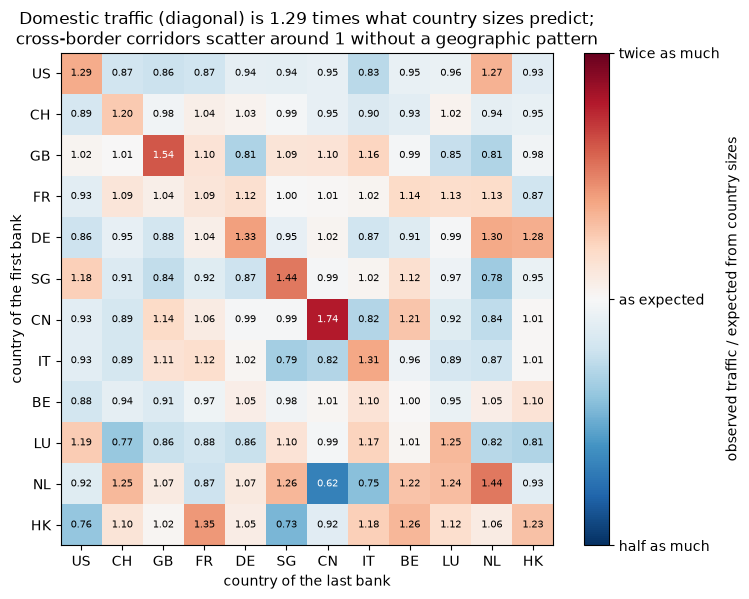

In [9]:
top = countries.country.head(12).tolist()
mat = q("SELECT first_country, last_country, observed / expected AS ratio FROM corridor").pivot(index="first_country", columns="last_country", values="ratio").reindex(index=top, columns=top)
fig, ax = plt.subplots(figsize=(8, 6.4))
im = ax.imshow(np.log2(mat.to_numpy(dtype=float)), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(top)))
ax.set_xticklabels(top)
ax.set_yticks(range(len(top)))
ax.set_yticklabels(top)
for i in range(len(top)):
    for j in range(len(top)):
        v = mat.iloc[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(np.log2(v)) > 0.6 else "black")
ax.set_xlabel("country of the last bank")
ax.set_ylabel("country of the first bank")
cbar = fig.colorbar(im, ax=ax, ticks=[-1, 0, 1])
cbar.ax.set_yticklabels(["half as much", "as expected", "twice as much"])
cbar.set_label("observed traffic / expected from country sizes")
d = dom.set_index("kind")
ax.set_title(f"Domestic traffic (diagonal) is {d.loc['domestic (same country)', 'ratio']:.2f} times what country sizes predict;\n"
             "cross-border corridors scatter around 1 without a geographic pattern")
eda.save(fig, "N2_corridor_ratios")
plt.show()

**Result: H-N2 held only as a first approximation.** Country sizes explain the broad picture, and domestic payments are more common than sizes alone predict (ratio in the table). But individual corridors miss the prediction by a wide margin in both directions (spread table), and the misses do not line up with geography. The next section looks for their source.

## 4. Bank pairs: where the traffic really sits (H-N5)

In [10]:
con.execute("CREATE OR REPLACE TEMP TABLE pair AS SELECT first_bank, last_bank, count(*) AS n FROM net GROUP BY 1, 2")
pairs = q("SELECT n FROM pair ORDER BY 1 DESC")
cum = pairs.n.cumsum() / N
n_pairs = len(pairs)
possible = float(q("SELECT (SELECT count(*) FROM bank WHERE as_first > 0) * 1.0 * (SELECT count(*) FROM bank WHERE as_last > 0) AS p").loc[0, "p"])
print(f"Bank pairs with at least one payment: {n_pairs:,} = {100 * n_pairs / possible:.2f}% of all possible first-bank x last-bank pairs")
print(f"Busiest 1% of pairs: {100 * cum.iloc[n_pairs // 100 - 1]:.1f}% of payments | busiest 10%: {100 * cum.iloc[n_pairs // 10 - 1]:.1f}%")
print(f"Pairs with a single payment: {int((pairs.n == 1).sum()):,} ({100 * (pairs.n == 1).mean():.1f}% of pairs) | busiest pair: {int(pairs.n.iloc[0]):,} payments")
con.execute("CREATE OR REPLACE TEMP TABLE top_pair AS SELECT * FROM pair ORDER BY n DESC LIMIT 8")
q("""
    SELECT t.first_bank, t.last_bank, t.n AS payments,
           count(DISTINCT net.ordering_account) FILTER (WHERE NOT net.path_first_differs) AS sender_accounts_at_first_bank,
           max(a.n_acc) AS payments_of_busiest_sender_account
    FROM top_pair t
    JOIN net ON net.first_bank = t.first_bank AND net.last_bank = t.last_bank
    JOIN (SELECT first_bank, last_bank, ordering_account, count(*) AS n_acc FROM net
          WHERE (first_bank, last_bank) IN (SELECT first_bank, last_bank FROM top_pair) GROUP BY 1, 2, 3) a
      ON a.first_bank = t.first_bank AND a.last_bank = t.last_bank
    GROUP BY 1, 2, 3 ORDER BY 3 DESC
""")

Bank pairs with at least one payment: 964,733 = 1.39% of all possible first-bank x last-bank pairs
Busiest 1% of pairs: 35.9% of payments | busiest 10%: 71.7%
Pairs with a single payment: 393,075 (40.7% of pairs) | busiest pair: 22,145 payments


,first_bank,last_bank,payments,sender_accounts_at_first_bank,payments_of_busiest_sender_account
0,0001MQM0,0009TNT0,22145,2,19383
1,0032MYK0,0010ALT0,18582,1367,1106
2,0065SGS0,0472US30,12207,26,3224
3,0119JPJ0,0072AEA0,7640,672,575
4,0041PAP0,0021AU20,6789,78,1168
5,0172CHZ0,0026FIH0,6711,15,3253
6,0098DEF0,0084ESM0,6395,321,734
7,0097IT20,0004IMD0,6198,469,374


In [11]:
# How much of a corridor's surplus comes from one pair of banks? The ten most over-used large cross-border corridors.
q("""
    WITH c AS (SELECT * FROM corridor WHERE first_country <> last_country AND expected >= 2000 ORDER BY observed / expected DESC LIMIT 10),
         p AS (SELECT substr(first_bank, 5, 2) AS first_country, substr(last_bank, 5, 2) AS last_country, max(n) AS busiest_pair_payments, count(*) AS bank_pairs
               FROM pair GROUP BY 1, 2)
    SELECT c.first_country, c.last_country, c.observed, round(c.expected) AS expected, c.observed / c.expected AS ratio,
           p.bank_pairs, p.busiest_pair_payments, 100.0 * p.busiest_pair_payments / c.observed AS pct_of_corridor_from_busiest_pair
    FROM c JOIN p USING (first_country, last_country) ORDER BY ratio DESC
""").round(2)

,first_country,last_country,observed,expected,ratio,bank_pairs,busiest_pair_payments,pct_of_corridor_from_busiest_pair
0,CN,LI,7463,"2,212.000",3.370,107,5842,78.280
1,EG,US,5250,"2,074.000",2.530,164,1811,34.500
2,PL,DE,5686,"2,294.000",2.480,257,1935,34.030
3,IE,CN,5533,"2,410.000",2.300,152,2454,44.350
4,IT,IM,12657,"5,795.000",2.180,51,6198,48.970
5,UG,US,4709,"2,183.000",2.160,204,2809,59.650
6,TR,CH,9737,"4,814.000",2.020,305,4731,48.590
7,DE,ES,13469,"6,772.000",1.990,1015,6395,47.480
8,GB,SE,3717,"2,064.000",1.800,333,2455,66.050
9,VN,CH,4666,"2,685.000",1.740,220,1972,42.260


**Result: H-N5 held in part.** Only a small fraction of the possible bank pairs is ever used, and a small fraction of those carries most of the traffic. The most over-used corridors owe a large part of their volume to a single pair of banks, so corridors are not drawn country by country: they are the by-product of which banks are connected. The "few very large sender accounts" part holds for some of the busiest pairs and not for others (first table: from 2 sender accounts to more than a thousand).

## 5. How are intermediaries chosen? (H-N3, H-N4, H-N6)

### 5.1 Geography (H-N4)
If intermediaries sat near the route, they would share a country with the first or last bank far more often than chance. Chance = the share expected if the intermediary's country were unrelated to the ends.

In [12]:
geo = q("""
    SELECT count(*)                                              AS intermediary_slots,
           100 * avg((country = first_country)::INT)             AS pct_same_country_as_first_bank,
           100 * avg((country = last_country)::INT)              AS pct_same_country_as_last_bank,
           100 * avg((bank = first_bank OR bank = last_bank)::INT) AS pct_same_bank_as_an_end
    FROM mid
""")
chance = q(f"""
    WITH m AS (SELECT country AS c, count(*) * 1.0 / {N_MID} AS p FROM mid GROUP BY 1),
         f AS (SELECT first_country AS c, count(*) * 1.0 / {N_MID} AS p FROM mid GROUP BY 1),
         l AS (SELECT last_country AS c, count(*) * 1.0 / {N_MID} AS p FROM mid GROUP BY 1)
    SELECT (SELECT 100 * sum(m.p * f.p) FROM m JOIN f USING (c)) AS chance_same_as_first,
           (SELECT 100 * sum(m.p * l.p) FROM m JOIN l USING (c)) AS chance_same_as_last
""")
pd.concat([geo, chance], axis=1).round(3)

,intermediary_slots,pct_same_country_as_first_bank,pct_same_country_as_last_bank,pct_same_bank_as_an_end,chance_same_as_first,chance_same_as_last
0,5815715,5.681,6.369,0.695,5.683,6.370


### 5.2 Size (H-N6)
If intermediaries were drawn in proportion to a bank's ordinary traffic, a group of banks holding 10% of the end-of-route slots would also hold 10% of the intermediary slots: ratio 1. Banks are grouped by how often they appear as first or last bank.

In [13]:
tiers = q(f"""
    SELECT CASE WHEN as_first + as_last >= 200000 THEN '1. 200,000+'
                WHEN as_first + as_last >= 50000  THEN '2. 50,000 to 199,999'
                WHEN as_first + as_last >= 10000  THEN '3. 10,000 to 49,999'
                WHEN as_first + as_last >= 2000   THEN '4. 2,000 to 9,999'
                WHEN as_first + as_last >= 200    THEN '5. 200 to 1,999'
                ELSE '6. under 200' END                              AS appearances_as_first_or_last_bank,
           count(*)                                                  AS banks,
           100.0 * sum(as_first + as_last) / (2.0 * {N})             AS pct_of_end_slots,
           100.0 * sum(as_intermediary) / {N_MID}                    AS pct_of_intermediary_slots,
           sum((as_intermediary = 0)::INT)                           AS banks_never_an_intermediary
    FROM bank GROUP BY 1 ORDER BY 1
""")
tiers["ratio"] = tiers.pct_of_intermediary_slots / tiers.pct_of_end_slots
never = int(tiers.banks_never_an_intermediary.sum())
print(f"Banks never used as an intermediary: {never:,} of {int(tiers.banks.sum()):,}")
tiers.round(3)

Banks never used as an intermediary: 1,221 of 8,727


,appearances_as_first_or_last_bank,banks,pct_of_end_slots,pct_of_intermediary_slots,banks_never_an_intermediary,ratio
0,"1. 200,000+",4,5.236,9.629,0.000,1.839
1,"2. 50,000 to 199,999",50,20.046,30.173,0.000,1.505
2,"3. 10,000 to 49,999",368,41.010,43.164,0.000,1.053
3,"4. 2,000 to 9,999",1062,23.015,11.996,2.000,0.521
4,"5. 200 to 1,999",2609,9.619,4.526,10.000,0.471
5,6. under 200,4634,1.074,0.512,"1,209.000",0.477


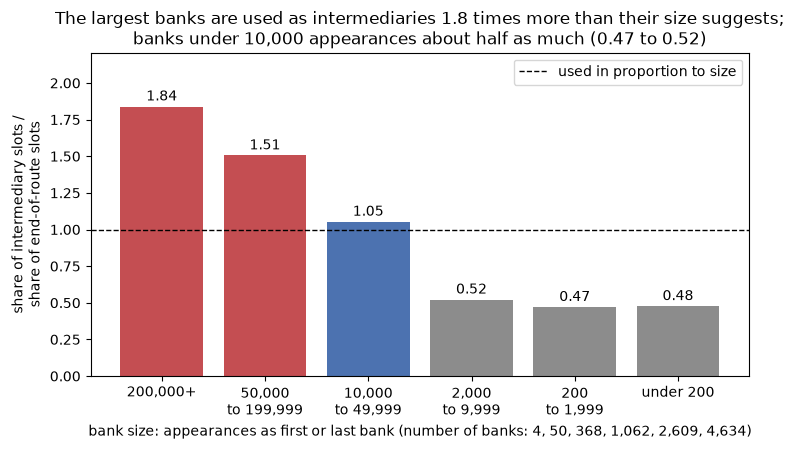

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
labels = [t.split(". ", 1)[1].replace(" to ", "\nto ") for t in tiers.appearances_as_first_or_last_bank]
bars = ax.bar(labels, tiers.ratio, color=[RED if r > 1.2 else (BLUE if r > 0.8 else GREY) for r in tiers.ratio])
ax.bar_label(bars, fmt="%.2f", padding=2)
ax.axhline(1, color="black", ls="--", lw=1, label="used in proportion to size")
ax.set_ylim(0, tiers.ratio.max() * 1.2)
ax.set_xlabel("bank size: appearances as first or last bank (number of banks: " + ", ".join(f"{int(n):,}" for n in tiers.banks) + ")")
ax.set_ylabel("share of intermediary slots /\nshare of end-of-route slots")
ax.legend()
big = tiers.iloc[0]
small = tiers.iloc[3:]
ax.set_title(f"The largest banks are used as intermediaries {big.ratio:.1f} times more than their size suggests;\n"
             f"banks under 10,000 appearances about half as much ({small.ratio.min():.2f} to {small.ratio.max():.2f})")
eda.save(fig, "N3_intermediary_by_bank_size")
plt.show()

### 5.3 Currency (H-N3)
For the six largest currencies: where do the intermediaries sit? The baseline is the last row, all currencies together.

In [15]:
EURO = "('DE','FR','IT','BE','LU','NL','ES','AT','FI','IE','PT','GR')"
cur = q(f"""
    SELECT currency_code, count(*) AS intermediary_slots,
           100 * avg((country = 'US')::INT) AS pct_in_US, 100 * avg((country IN {EURO})::INT) AS pct_in_12_euro_countries,
           100 * avg((country = 'GB')::INT) AS pct_in_GB, 100 * avg((country = 'CH')::INT) AS pct_in_CH
    FROM mid WHERE currency_code IN ('USD', 'EUR', 'GBP', 'CHF', 'SGD', 'CNY') GROUP BY 1 ORDER BY 2 DESC
""")
allc = q(f"""
    SELECT 'all currencies' AS currency_code, count(*) AS intermediary_slots,
           100 * avg((country = 'US')::INT) AS pct_in_US, 100 * avg((country IN {EURO})::INT) AS pct_in_12_euro_countries,
           100 * avg((country = 'GB')::INT) AS pct_in_GB, 100 * avg((country = 'CH')::INT) AS pct_in_CH
    FROM mid
""")
pd.concat([cur, allc], ignore_index=True).round(2)

,currency_code,intermediary_slots,pct_in_US,pct_in_12_euro_countries,pct_in_GB,pct_in_CH
0,EUR,1925966,17.070,30.910,6.030,10.180
1,USD,1008740,20.620,26.850,6.190,10.260
2,GBP,509100,17.430,27.230,7.840,10.310
3,CHF,460989,17.190,27.960,6.080,12.210
4,SGD,208110,17.850,27.330,6.300,10.570
5,CNY,188439,17.440,26.680,6.170,10.480
6,all currencies,5815715,17.940,28.530,6.310,10.500


**Result.** H-N4 was **rejected**: an intermediary shares a country with either end of the route at about the chance rate, so geography plays no part. H-N6 **held**: the intermediary is drawn from the whole population of banks, with large banks favoured well beyond their size and small banks used about half as often as their size suggests (table and chart in 5.2). H-N3 **held weakly**: intermediaries are a few points more likely to sit in the currency's home area (dollar in the US, euro in euro countries, pound in the UK, franc in Switzerland), far from "dollar payments go through US banks". The direction of this link is settled by Dashboard 3 and notebook 09 (section 3.1): the currency is taken from a bank on the route, mostly the first. So the banks on the route decide the currency, and an intermediary in the US makes a dollar payment more likely, not the other way round.

### 5.4 A by-product for the currency dashboard: each country's home currency, from the data

Among payments that stay inside one country, which currency is the most common, and how dominant is it? This gives a home currency per country without any outside reference table.

In [16]:
home = q("""
    WITH c AS (SELECT first_country AS country, currency_code, count(*) AS n FROM net WHERE first_country = last_country GROUP BY 1, 2),
         r AS (SELECT *, row_number() OVER (PARTITION BY country ORDER BY n DESC, currency_code) AS rk, sum(n) OVER (PARTITION BY country) AS domestic_payments FROM c)
    SELECT country, currency_code AS home_currency, domestic_payments, 100.0 * n / domestic_payments AS pct_of_domestic_payments
    FROM r WHERE rk = 1 ORDER BY domestic_payments DESC
""")
solid = home[home.domestic_payments >= 200]
print(f"Countries with domestic payments: {len(home)} | with 200+ domestic payments: {len(solid)}")
print(f"Share of the home currency among those {len(solid)} countries: median {solid.pct_of_domestic_payments.median():.1f}%, lowest {solid.pct_of_domestic_payments.min():.1f}%")
home.head(12).round(1)

Countries with domestic payments: 112 | with 200+ domestic payments: 35
Share of the home currency among those 35 countries: median 96.1%, lowest 83.7%


,country,home_currency,domestic_payments,pct_of_domestic_payments
0,US,USD,"395,503.000",96.900
1,CH,CHF,"78,058.000",96.100
2,GB,GBP,"67,479.000",96.100
3,DE,EUR,"35,277.000",98.700
4,FR,EUR,"32,889.000",98.400
5,SG,SGD,"21,983.000",95.600
6,CN,CNY,"20,474.000",94.800
7,IT,EUR,"13,206.000",98.200
8,LU,EUR,"10,683.000",98.500
9,BE,EUR,"9,767.000",98.100


## 6. Results: reconstructed rules (all checked on 10,000,000 rows)

Every number below is printed by a cell above.

| ID | Rule: condition → effect | Size and scope | Evidence | Confidence |
|---|---|---|---|---|
| R-N1 | Traffic is spread over thousands of banks with a long tail; no single bank dominates. | 8,727 banks in 229 countries. As first bank: top 10 hold 8.9%, top 100 hold 32.6%, 236 banks carry half, 1,596 carry 90%. | Section 2, chart N1 | High |
| R-N2 | A country's traffic follows its number of banks. | 228 first-bank countries; correlation between banks per country and traffic 0.953. Top 5 countries (US, CH, GB, FR, DE) hold 40.8%, top 20 hold 73.3%. | Section 3 | High |
| R-N3 | Payments stay inside one country more often than country sizes predict. | 7.28% of routes are domestic against 5.62% expected: 1.295 times. | Section 3, chart N2 | High for the average. The uplift differs by country (0.28 to 1.90 among the 17 largest). |
| R-N4 | Cross-border corridors are not drawn country by country. They are the by-product of which bank pairs are connected. | Among 755 large cross-border corridors the ratio to "big sends to big" runs from 0.04 to 3.37 (middle 90%: 0.61 to 1.36). In the ten most over-used corridors a single pair of banks supplies 34% to 78% of the volume. | Sections 3 and 4 | High |
| R-N5 | Only a small, very unequal set of bank pairs is used. | 964,733 pairs = 1.39% of the possible ones. The busiest 1% of pairs carry 35.9% of payments, the busiest 10% carry 71.7%; 40.7% of pairs have a single payment. | Section 4 | High |
| R-N6 | An intermediary is drawn from the whole population of banks, without regard to the route's geography. | Same country as the first bank: 5.681% of 5,815,715 intermediary slots, against 5.683% by chance. Same country as the last bank: 6.369% against 6.370%. The intermediary is one of the two end banks in 0.695% of slots. | Section 5.1 | High |
| R-N7 | Large banks are favoured as intermediaries beyond their size; small banks are used about half as often as their size suggests. | Ratio of intermediary share to end-of-route share: 1.84 for the 4 largest banks, 1.51 for the next 50, 1.05 for the next 368, then 0.52, 0.47 and 0.48 for the three groups of smaller banks. Intermediary traffic is therefore more concentrated: 91 banks carry half (236 for first banks); top 10 hold 19.2%. 1,221 banks are never an intermediary. | Sections 2 and 5.2, charts N1 and N3 | High for the pattern. Medium for the mechanism (see unexplained). |
| R-N8 | The currency shifts the intermediaries a few points towards its home area. | Dollar: 20.6% of intermediaries in the US (all currencies: 17.9%). Euro: 30.9% in 12 euro countries (28.5%). Pound: 7.8% in the UK (6.3%). Franc: 12.2% in Switzerland (10.5%). | Section 5.3 | High for the observation. Direction: the route decides the currency (Dashboard 3, notebook 09 section 3.1). |

### Hypotheses that did not hold

- **H-N1, most routes pass through a few US, Swiss and UK hubs: only partly.** Hubs exist (R-N7), but only 27.3% of multi-bank routes touch one of the ten biggest, and those ten sit in nine different countries. Banks in the US, Switzerland and the UK fill 34.8% of intermediary slots, close to their share of all traffic.
- **H-N2, corridor volume = product of country sizes: rejected as a rule** (R-N4). It is a usable first approximation only.
- **H-N4, intermediaries sit near the route: rejected** (R-N6). The match with chance is exact to two decimals.
- **H-N3, the currency decides the intermediary: weak** (R-N8). A shift of 2 to 3 points, not a routing rule.

### What is still unexplained

1. **Why a given pair of banks is busy.** Some of the busiest pairs are fed by a handful of very large sender accounts (2, 15, 26 accounts), others by hundreds or more than a thousand. So part of the answer is large accounts and part is a link between the customers of two banks; we did not separate the two.
2. **The exact weight used to pick an intermediary** (R-N7). The flat ratio of about 0.5 for every group of smaller banks, next to ratios well above 1 for large banks, would fit a mixture: roughly half of the picks drawn from all banks in proportion to size, the other half drawn only from large banks. We did not test this further.
3. ~~The direction of the currency link~~ **Explained** (R-N8): the currency is taken from one of the banks on the route, mostly the first (Dashboard 3; notebook 09 section 3.1), so more intermediaries in an area make its currency more likely.
4. **Why the domestic uplift differs by country** (R-N3).

### What this may mean in the real world (interpretation, not observation)

- **R-N1, R-N2:** international banking has a few very large institutions and a long tail of small ones, and large financial centres have many banks.
- **R-N3:** customers pay suppliers, employees and family in their own country more often than chance would give.
- **R-N4, R-N5:** trade runs along business relationships, not between countries as such. One company paying its suppliers at one foreign bank is enough to create a "corridor". *Alternative:* the generator may simply give each sender account a short fixed list of receivers; that would produce the same picture, and the account-level evidence favours it.
- **R-N6 is where the dataset departs from reality.** Real correspondent banks are chosen for the currency and the destination: a dollar payment to Brazil clears through a bank in New York. Here intermediaries are picked at random by size, so the middle of a route carries no information about the corridor.
- **R-N7:** large banks do act as correspondents for many smaller ones, which is why they appear in the middle of other banks' payments.

### What other dashboards can rely on

- Use the route's ends (first and last bank in the path) for country questions about the route; `sender_country` and `receiver_country` describe the parties' own banks and differ in about 5% of rows each.
- Intermediaries are independent of the route's countries, so they cannot explain country or corridor effects elsewhere.
- A country's "home currency" can be read from the data itself, without any outside lookup table: section 5.4 lists the most common currency of each country's domestic payments and how dominant it is.
